# Assignment 1 · Part 2 — Frequencies, Pyramids and Blending


| module | section | what it holds |
|---|---|---|
| `hybrid.py` | 2.1 | `make_hybrid`, `log_fft`, low/high-pass |
| `aliasing.py` | 2.2 | naive vs anti-aliased subsampling, test patterns |
| `pyramids.py` | 2.3 | `reduce`, `expand`, `gaussian_pyramid`, `laplacian_pyramid`, `reconstruct` |
| `blending.py` | 2.4 | `multires_blend`, masks, baseline blends |
| `viz.py` | all | every figure below |


In [ ]:
%matplotlib inline
import config                                   # sets up sys.path so `cvlib` and the modules import
from config import IMAGES_DIR, SHARED_IMAGES_DIR, FIG_DIR, make_folders
make_folders()

import numpy as np
from cvlib import load_image, save_image, gaussian_blur
import hybrid, aliasing, pyramids, blending, viz, synthetic
from hybrid import make_hybrid, to_gray, center_crop_resize
from aliasing import aliasing_comparison, zone_plate, stripes
from pyramids import gaussian_pyramid, laplacian_pyramid, reconstruct
from blending import (multires_blend, direct_paste, feather_blend, vertical_mask,
                      circle_mask, ellipse_mask, polygon_mask)
from align_images import align_images, show_with_grid, similarity_from_two_points          # starter-pack aligner (needs opencv)

NO_SHRINK = 10 ** 6        # cvlib.load_image shrinks images above max_side; point coordinates need full size

def find_image(filename):
    """images/ inside part2 first, then the shared cv_assignment1/images folder."""
    for folder in (IMAGES_DIR, SHARED_IMAGES_DIR):
        if filename and (folder / filename).exists():
            return folder / filename
    return None

def load_or_demo(filename, demo, gray=False, max_side=NO_SHRINK):
    """Load an image by file name; if it is missing, fall back to a generated demo image
    so the notebook still runs (a [demo] note is printed)."""
    path = find_image(filename)
    if path is not None:
        return load_image(path, gray=gray, max_side=max_side)
    print(f"[demo] {filename!r} not found -> using synthetic '{demo}' image")
    img = synthetic.DEMOS[demo]()
    return to_gray(img) if gray else img

def match_shape(a, b):
    """If b is not the same shape as a, crop+resize it (quick fallback; real pairs should be
    aligned with align_images and two eye points)."""
    if a.shape != b.shape:
        print(f"[note] shapes differ {a.shape} vs {b.shape}; quick centre-crop used")
        b = center_crop_resize(b, a.shape)
    return b

In [ ]:
HYBRID_GRAY = True        # the handout shows grayscale hybrids (also much faster); False = colour

# --- 2.1: low = image whose LOW frequencies are kept, high = image whose HIGH frequencies are kept.
#     Points are matched pairs (x, y); `high` is warped onto `low`. None = no alignment (same-size images).
HYBRID_PAIRS = [
    dict(name="man_cat", low="hybrid_man.jpg", high="hybrid_cat.jpg",
         pts_low=[(299, 341), (443, 332)], pts_high=[(605, 290), (760, 372)],    # eyes, from the starter README
         sigma_low=10, sigma_high=5),
    dict(name="pair2", low="pair2_a.jpeg", high="pair2_b.jpg",                   # your own pair 1
         crop_low=(50, 336, 120, 400), crop_high=(0, 300, 130, 420),             # (top, bottom, left, right): face area only
         pts_low=[(87, 90), (177, 78)], pts_high=[(82, 92), (142, 118)],         # eyes, in CROPPED coordinates
         sigma_low=6, sigma_high=3),
    dict(name="pair3", low="pair3_smile.png", high="pair3_serious.png",          # your own pair 2: same face, smiling + serious
         crop_low=(60, 380, 190, 510), crop_high=(60, 380, 180, 500),            # (top, bottom, left, right): face area only
         pts_low=[(136, 116), (186, 114)], pts_high=[(136, 126), (189, 120)],    # eyes, in CROPPED coordinates
         sigma_low=6, sigma_high=3),
    dict(name="pair4", low="pair4_front.jpeg", high="pair4_profile.jpeg",        # extra: front view + side view (expected to fail)
         crop_high=(0, 760, 0, 735),                                             # drops a black line along the bottom edge
         pts_low=[(368, 408), (370, 640)], pts_high=[(216, 312), (175, 455)],    # middle of the eyes + mouth / eye + mouth
         sigma_low=6, sigma_high=3),
]
# --- 2.2 aliasing: a structured image and a real texture
ALIAS_IMAGES = ["rings.png", "brick.png"]
CLEAN_SIGMA = 3          # 2.2: smallest sigma (k = 4) with no false circles; confirm with the sweep below
# --- 2.3 pyramids: any image
PYRAMID_IMAGE = "facade.png"
# --- 2.4 blending: oraple, then an irregular-mask pair (eye on the palm)
OR_A, OR_B = "apple.jpg", "orange.jpg"
HAND, EYE = "hand.jpg", "eye.jpg"
HAND_PTS, EYE_PTS = [(170, 400), (390, 410)], [(165, 255), (470, 265)]          # from the starter README
# --- 2.4: YOUR TWO OWN BLENDS (the oraple above and the hand/eye practice pair do not count as these two).
#     `obj` is warped onto `base` with align_images (two matching points on each, x y), the mask is drawn in
#     BASE coordinates, and the result is multires_blend(obj, base, mask): white = take `obj`.
#     mask kinds:  dict(kind="ellipse", center=(x, y), radii=(rx, ry), angle=0)
#                  dict(kind="polygon", points=[(x, y), ...])          (cv2.fillPoly, BASE coordinates)
#                  dict(kind="polygon_obj", points=[(x, y), ...])      (traced on the OBJECT image, then mapped onto the
#                                                                        base through the same two-point alignment)
#                  dict(kind="file", path="my_mask.png")               (white = take obj)
FACE_OUTLINE = [(300, 168), (370, 175), (430, 200), (452, 240), (470, 300), (473, 370), (466, 450), (452, 495),
                (444, 540), (438, 585), (405, 615), (360, 634), (300, 640), (240, 634), (195, 615), (162, 585),
                (156, 540), (148, 495), (134, 450), (127, 370), (130, 300), (148, 240), (170, 200), (230, 175)]
EYE_OUTLINE = [(110, 600), (170, 540), (240, 480), (330, 440), (420, 430), (510, 445), (590, 485), (660, 545), (700, 585),
               (690, 625), (640, 665), (570, 700), (480, 730), (390, 740), (300, 725), (220, 690), (150, 665), (105, 640)]
BLEND_PAIRS = [
    # a face on a pumpkin: eye centres of the face -> where the eyes should sit on the pumpkin's body
    dict(name="face_pumpkin", base="pumpkin_base.jpg", obj="face_obj.jpg",
         pts_base=[(213, 425), (341, 425)], pts_obj=[(216, 331), (381, 331)],
         mask=dict(kind="polygon_obj", points=FACE_OUTLINE), levels=5, sweep=(1, 3, 5, 7)),
    # an eye on the moon: inner and outer corner of the eye -> a pair of points across the moon's disc
    dict(name="eye_moon", base="moon_base.jpg", obj="eye_obj.jpg",
         pts_base=[(170, 464), (502, 436)], pts_obj=[(95, 635), (700, 583)],
         mask=dict(kind="polygon_obj", points=EYE_OUTLINE), levels=5, sweep=(1, 3, 5, 7)),
]
BLEND_FAVORITE = "eye_moon"     # gets the level-by-level M*L1, (1-M)*L2, sum figure


## 2.1 Hybrid images

`hybrid = gaussian_blur(A, σ_low) + (B − gaussian_blur(B, σ_high))`.
`B` is first warped onto `A` with `align_images` (two matching points).


man_cat:  sigma_low = 10,  sigma_high = 5


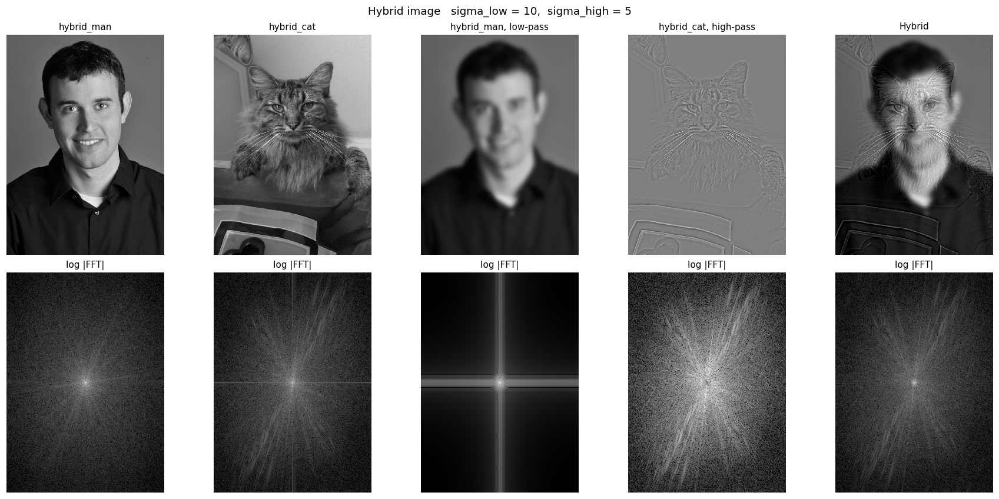

pair2:  sigma_low = 6,  sigma_high = 3


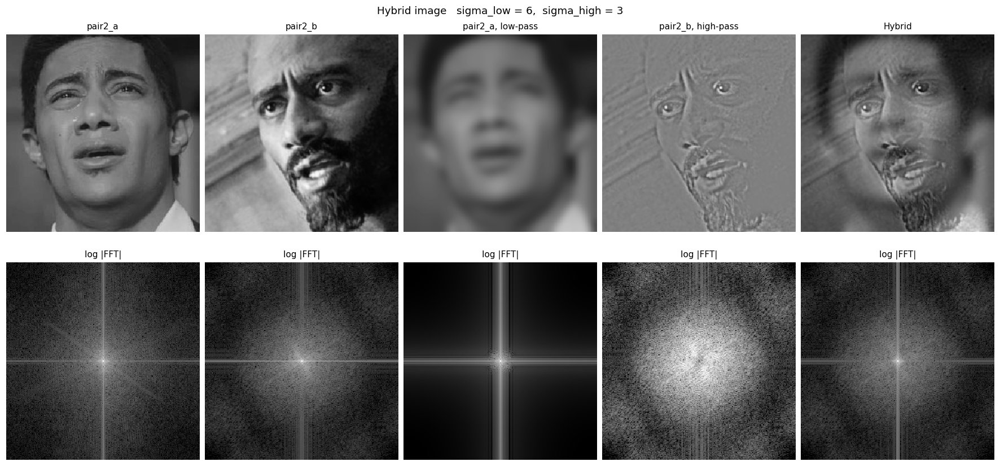

pair3:  sigma_low = 6,  sigma_high = 3


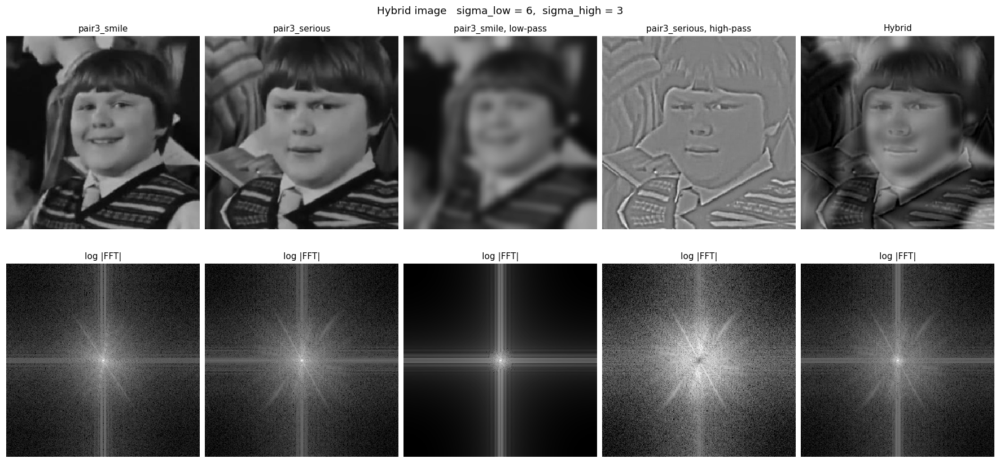

pair4:  sigma_low = 6,  sigma_high = 3


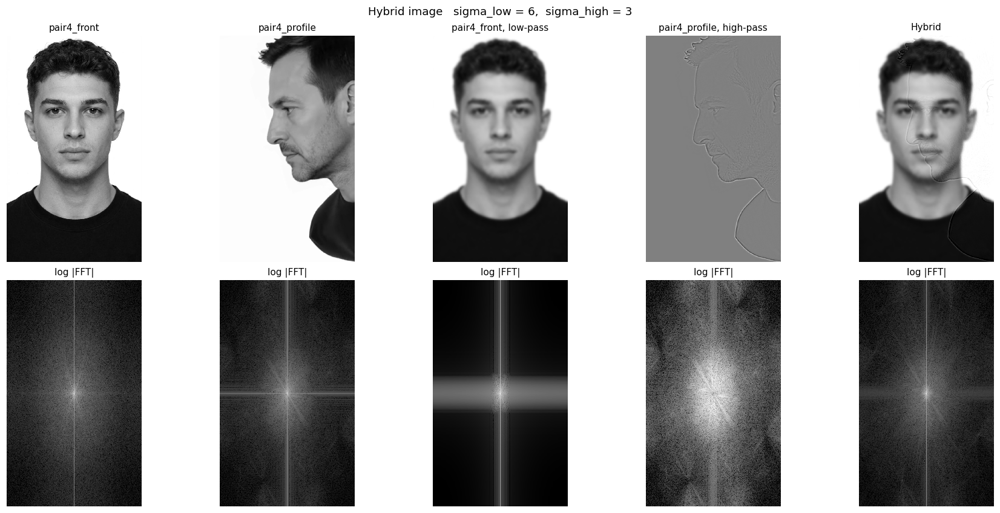

In [ ]:
def crop(img, box):
    # box = (top, bottom, left, right) in pixels; None = keep everything
    if box is None:
        return img
    t, b, l, r = box
    return img[t:b, l:r]

def prepare_pair(p):
    low = crop(load_or_demo(p["low"], "blobs", gray=HYBRID_GRAY), p.get("crop_low"))
    high = crop(load_or_demo(p["high"], "texture", gray=HYBRID_GRAY), p.get("crop_high"))
    if p["pts_low"] and p["pts_high"] and find_image(p["high"]):
        high = align_images(low, high, p["pts_low"], p["pts_high"])      # starter-pack aligner
    else:
        high = match_shape(low, high)
    return low, high

results = {}
for p in HYBRID_PAIRS:
    im_low, im_high = prepare_pair(p)
    res = make_hybrid(im_low, im_high, p["sigma_low"], p["sigma_high"])
    results[p["name"]] = res
    print(f"{p['name']}:  sigma_low = {p['sigma_low']},  sigma_high = {p['sigma_high']}")
    viz.show_hybrid_report(res, names=(p["low"].split('.')[0], p["high"].split('.')[0]),
                           save_path=FIG_DIR / f"2_1_{p['name']}_report.png")
    save_image(res["hybrid"], FIG_DIR / f"2_1_{p['name']}_hybrid.png")

### How it looks from far away
Each tile is drawn at its true pixel size: the smaller it gets, the further away you are, and the high-frequency image should disappear.

man_cat


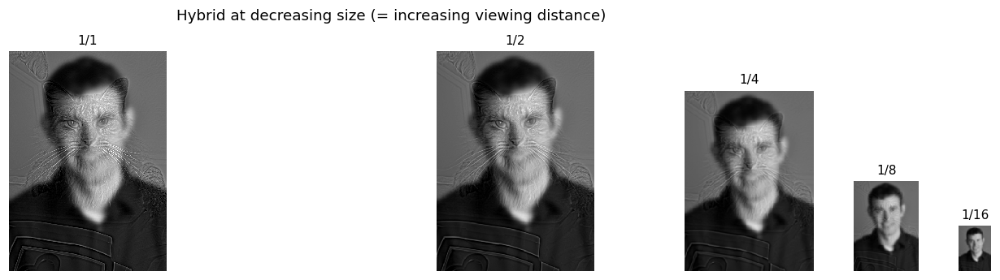

pair2


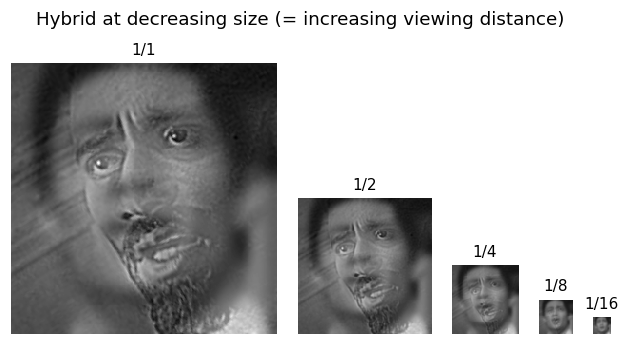

pair3


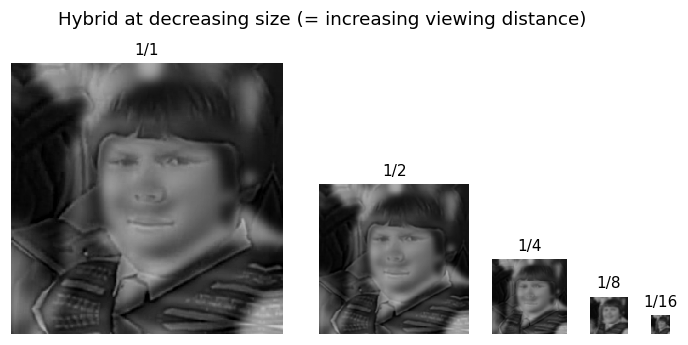

pair4


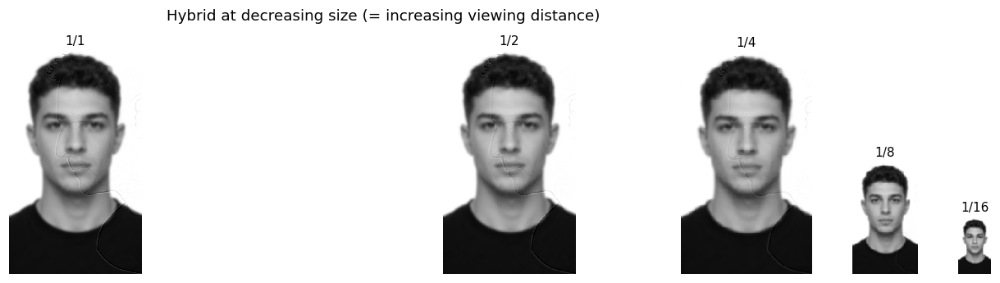

In [ ]:
for name, res in results.items():
    print(name)
    viz.show_distance_strip(res["hybrid"], levels=5, save_path=FIG_DIR / f"2_1_{name}_distance.png")

### Tuning the two σ values
Change `FAVORITE` and the two lists. Larger `σ_low` = blurrier low image. Larger `σ_high` = the high-pass keeps *less* (cutoff moves lower).

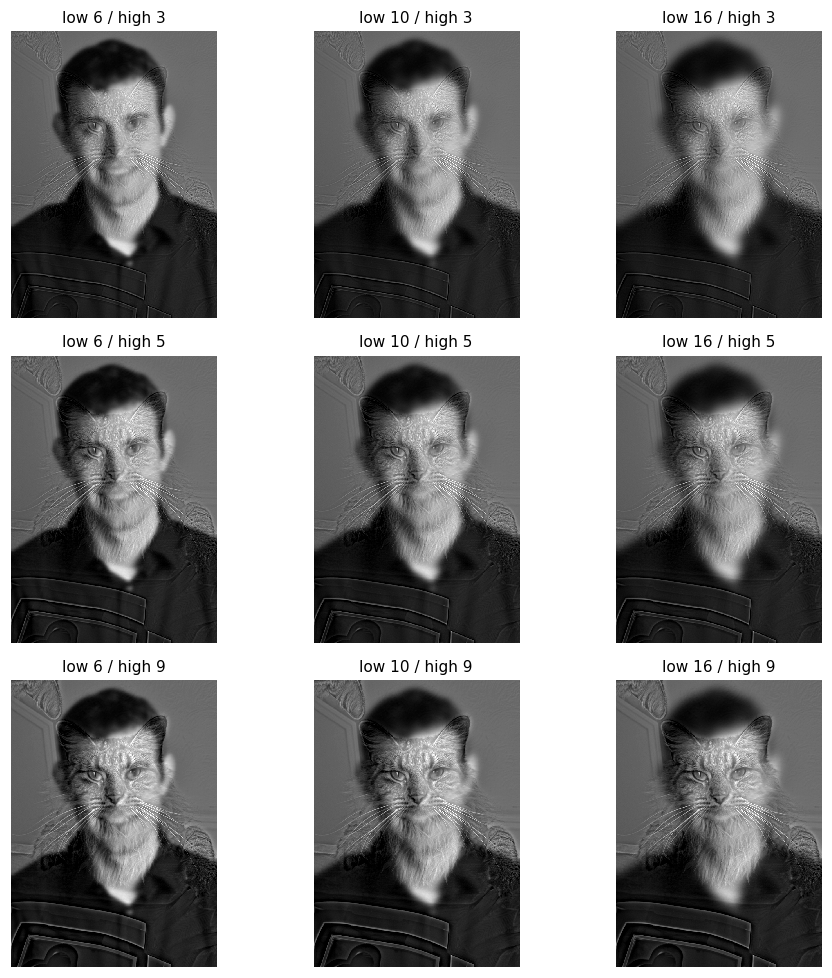

In [ ]:
FAVORITE = "man_cat"
r = results[FAVORITE]
viz.show_sigma_grid(make_hybrid, r["im_low"], r["im_high"],
                    sigma_lows=[6, 10, 16], sigma_highs=[3, 5, 9],
                    save_path=FIG_DIR / f"2_1_{FAVORITE}_sigma_grid.png")

## 2.2 Aliasing

Keeping every k-th pixel folds frequencies above the new Nyquist limit back as false low frequencies.
Blurring first (an anti-aliasing low-pass) removes them before they can fold. The spectra show the energy that folded back.
The images are shown blown back up to full size with nearest-neighbour pixels, so view them at 100% zoom.

rings.png (512, 512)


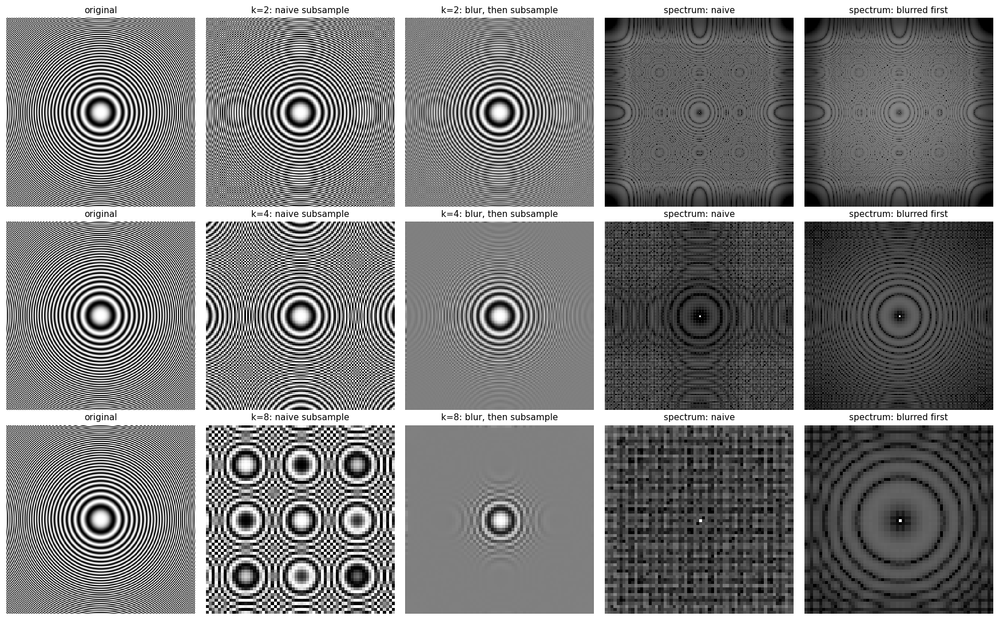

brick.png (512, 512)


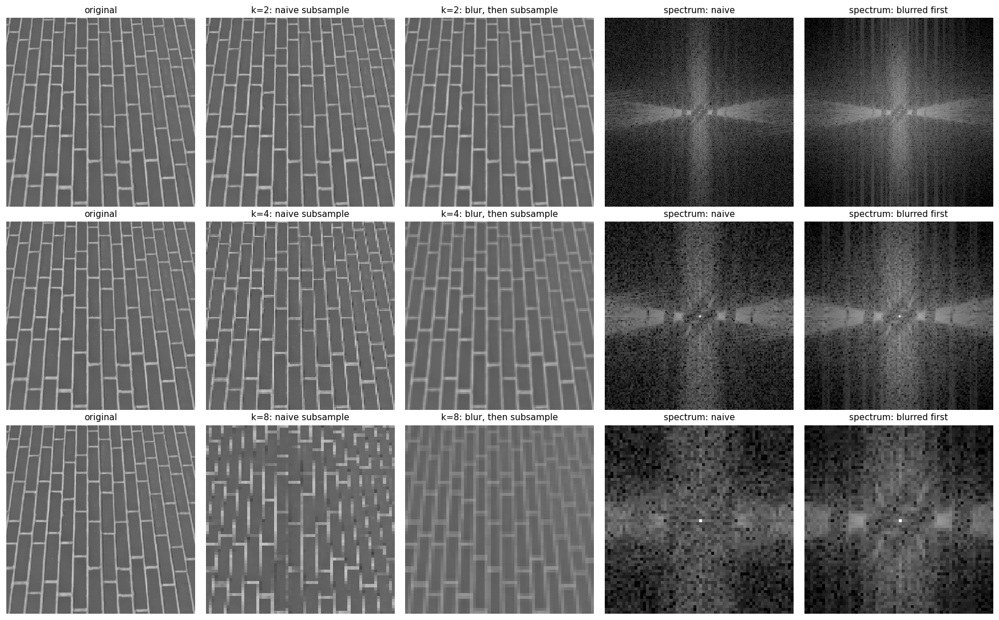

In [ ]:
for fname in ALIAS_IMAGES:
    im = load_or_demo(fname, "texture", gray=True)
    print(fname, im.shape)
    viz.show_aliasing(im, aliasing_comparison(im, ks=(2, 4, 8)),
                      save_path=FIG_DIR / f"2_2_{fname.split('.')[0]}.png")

A synthetic chirp sweeps through *all* frequencies, so it shows exactly where aliasing starts:

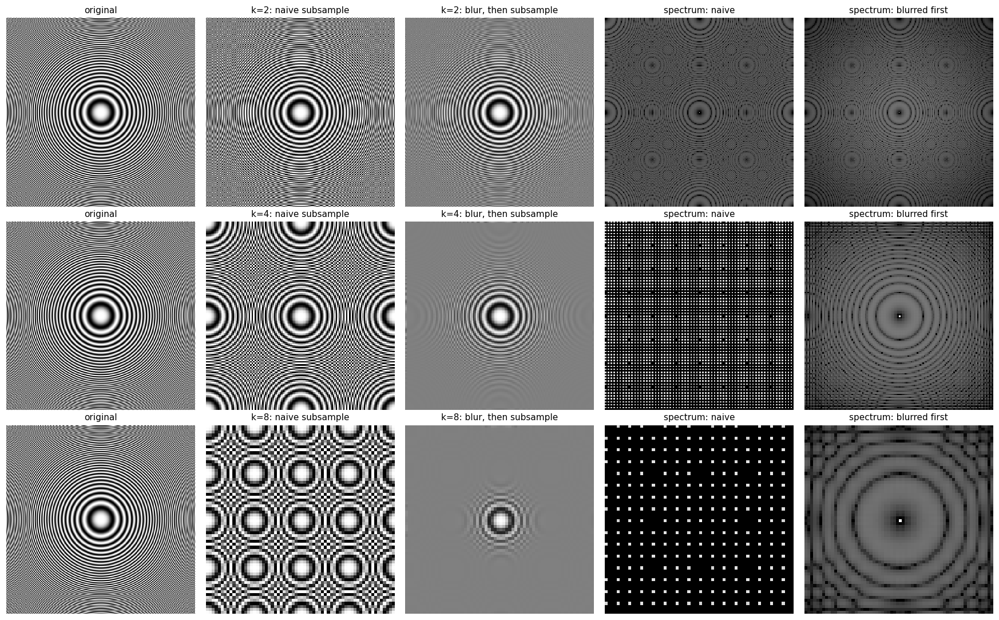

In [ ]:
chirp = zone_plate(512)
viz.show_aliasing(chirp, aliasing_comparison(chirp, ks=(2, 4, 8)), save_path=FIG_DIR / "2_2_chirp.png")

Effect of the pre-blur strength for one factor (`k = 4`): too small and aliasing stays; too large and the image is needlessly soft.

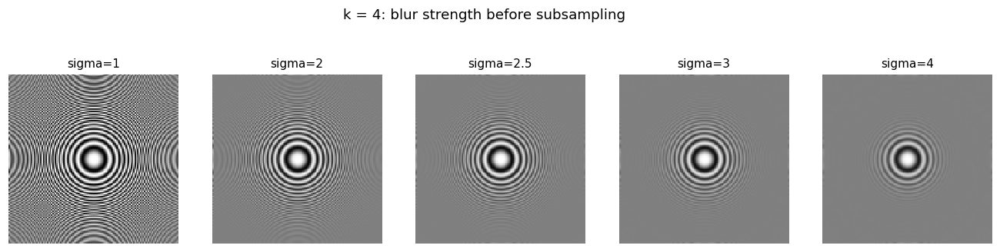

In [ ]:
k = 4
photo = load_or_demo(ALIAS_IMAGES[0], "texture", gray=True)
variants = [(f"sigma={s:g}", aliasing.antialiased_subsample(photo, k, sigma=s)) for s in (1, 2, 2.5, 3, 4)]
viz.show_row([np.repeat(np.repeat(v, k, 0), k, 1) for _, v in variants],
             [t for t, _ in variants], suptitle=f"k = {k}: blur strength before subsampling",
             size=3.0, save_path=FIG_DIR / "2_2_sigma_sweep.png")

### Smallest clean σ, and the two quarter-size results side by side
The handout's experiment on `rings.png`: shrink to 1/4 of the width and height (a) keeping every 4th pixel and (b) blurring first. The table measures the contrast left in the outer rings, which are too fine to survive a 4x shrink: a clean result is flat gray there, so leftover contrast = false circles. Confirm by eye on the sweep above.

naive            outer-ring std = 0.3528
sigma = 1         outer-ring std = 0.1668
sigma = 1.5       outer-ring std = 0.0746
sigma = 2         outer-ring std = 0.0283
sigma = 2.5       outer-ring std = 0.0109
sigma = 3         outer-ring std = 0.0061
sigma = 3.5       outer-ring std = 0.0048
sigma = 4         outer-ring std = 0.0042


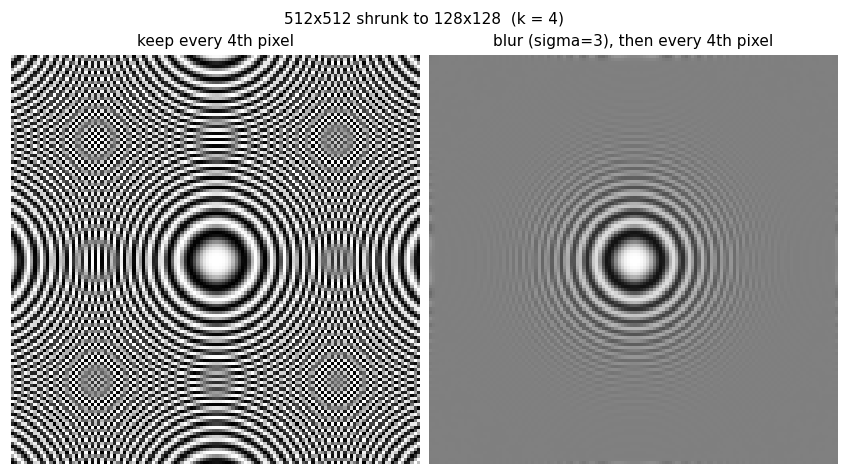

In [ ]:
ring = load_or_demo(ALIAS_IMAGES[0], "texture", gray=True)
k = 4
print(f"naive            outer-ring std = {aliasing.outer_ring_std(aliasing.subsample(ring, k)):.4f}")
for s in (1, 1.5, 2, 2.5, 3, 3.5, 4):
    print(f"sigma = {s:<4}      outer-ring std = {aliasing.outer_ring_std(aliasing.antialiased_subsample(ring, k, s)):.4f}")
viz.show_quarter_side_by_side(aliasing.subsample(ring, k), aliasing.antialiased_subsample(ring, k, CLEAN_SIGMA),
                              k, CLEAN_SIGMA, ring.shape, save_path=FIG_DIR / "2_2_rings_quarter.png")

## 2.3 Gaussian and Laplacian pyramids

Both `reduce` and `expand` blur with the handout's kernel `1/16 [1 4 6 4 1]` along x and y.
`reduce` blurs, then keeps every other row and column. `expand` puts each pixel at the top-left of a 2x2 block of zeros, blurs, and multiplies by 4

`G(i+1) = reduce(G(i))`, `L(i) = G(i) − expand(G(i+1))`; the last Laplacian level is the coarsest Gaussian
Because `G(i) = L(i) + expand(G(i+1))` holds by construction, the pyramid rebuilds the image exactly


level shapes: [(466, 512), (233, 256), (117, 128), (59, 64), (30, 32), (15, 16)]


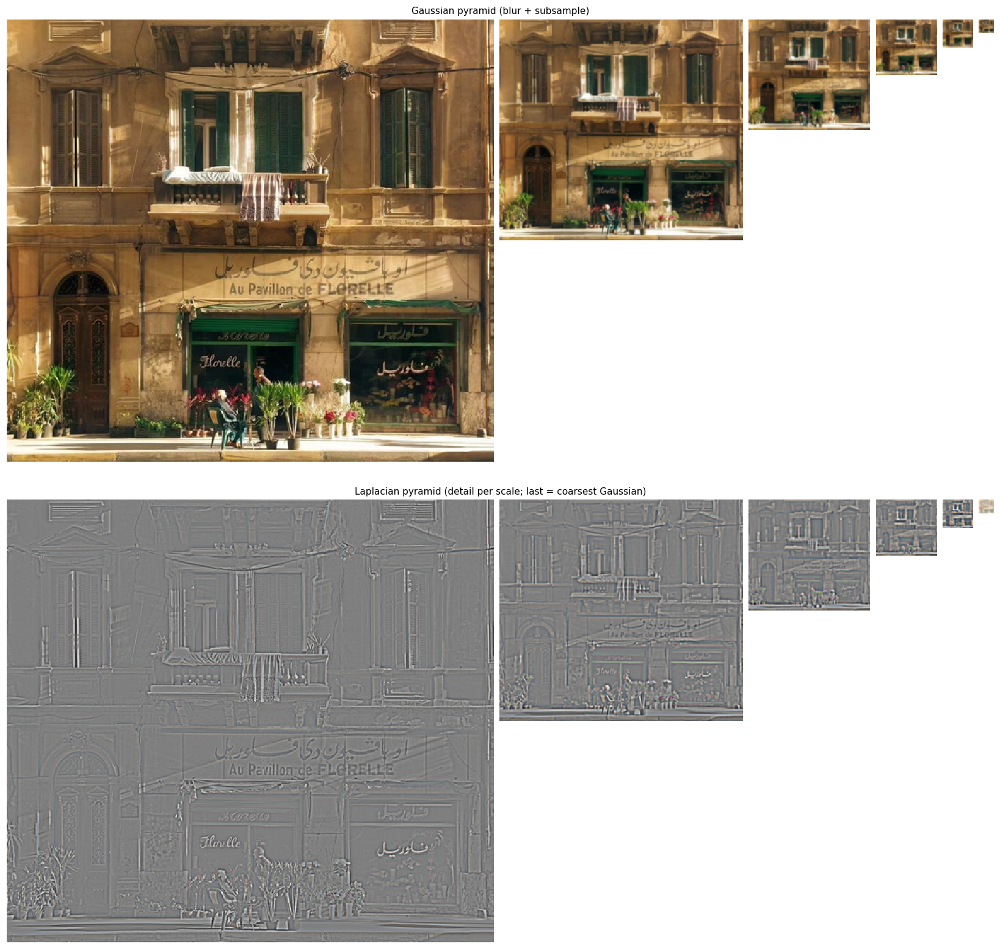

total pyramid size / image size = 1.3336   (limit 4/3 = 1.3333)


In [ ]:
img = load_or_demo(PYRAMID_IMAGE, "scene", max_side=512)
gpyr = gaussian_pyramid(img, levels=6)
lpyr = laplacian_pyramid(img, levels=6)
print("level shapes:", [p.shape[:2] for p in gpyr])
viz.show_pyramid_pair(gpyr, lpyr, save_path=FIG_DIR / "2_3_pyramids.png")
print(f"total pyramid size / image size = {pyramids.total_size_ratio(gpyr):.4f}   (limit 4/3 = {4/3:.4f})")


max |original - reconstruction| = 1.11e-16


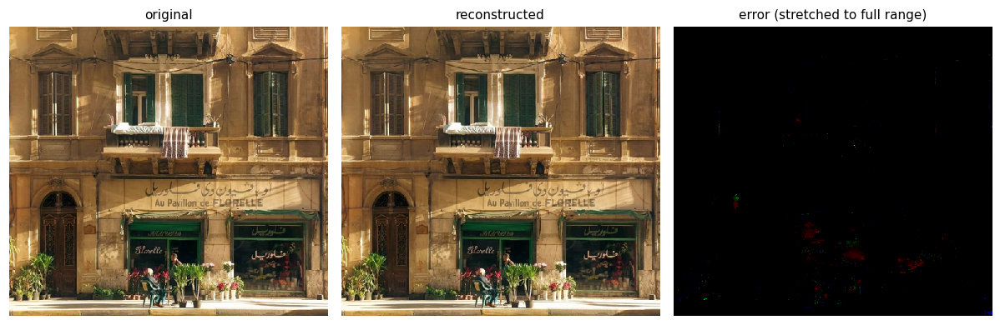

In [ ]:
rebuilt = reconstruct(lpyr)
viz.show_reconstruction(img, rebuilt, save_path=FIG_DIR / "2_3_reconstruction.png")

Each Laplacian level is a **band-pass** image (0 = mid-gray). Their spectra show which frequencies each level carries:

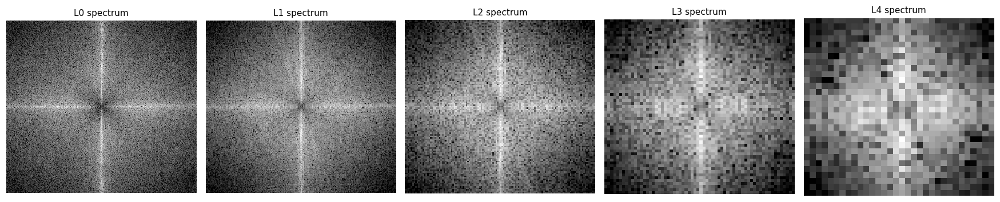

In [ ]:
import matplotlib.pyplot as plt
from hybrid import log_fft
fig, axes = plt.subplots(1, len(lpyr) - 1, figsize=(3.2 * (len(lpyr) - 1), 3.6))
for i, ax in enumerate(axes):
    f = log_fft(to_gray(lpyr[i]))
    ax.imshow(f, cmap="gray", vmin=np.percentile(f, 2), vmax=f.max()); ax.set_title(f"L{i} spectrum"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "2_3_band_spectra.png", dpi=150, bbox_inches="tight"); plt.show()

## 2.4 Multiresolution blending

Blend every Laplacian level with a mask that is blurred **more at coarse levels** (the mask's Gaussian pyramid), then collapse.
Two baselines show why this matters: a direct paste shows a hard seam, and a single-scale feather either ghosts or still shows the seam

### The oraple (vertical seam)

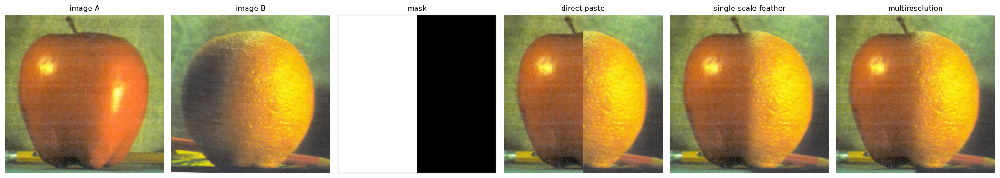

In [ ]:
A = load_or_demo(OR_A, "sunset", max_side=512)
B = match_shape(A, load_or_demo(OR_B, "bars", max_side=512))
mask = vertical_mask(A.shape)                    # left half from A, right half from B

direct  = direct_paste(A, B, mask)
feather = feather_blend(A, B, mask, sigma=15)
multi, parts = multires_blend(A, B, mask, levels=6, return_parts=True)

viz.show_blend_comparison(A, B, mask, [direct, feather, multi],
                          ["direct paste", "single-scale feather", "multiresolution"],
                          save_path=FIG_DIR / "2_4_oraple_comparison.png")
save_image(multi, FIG_DIR / "2_4_oraple.png")

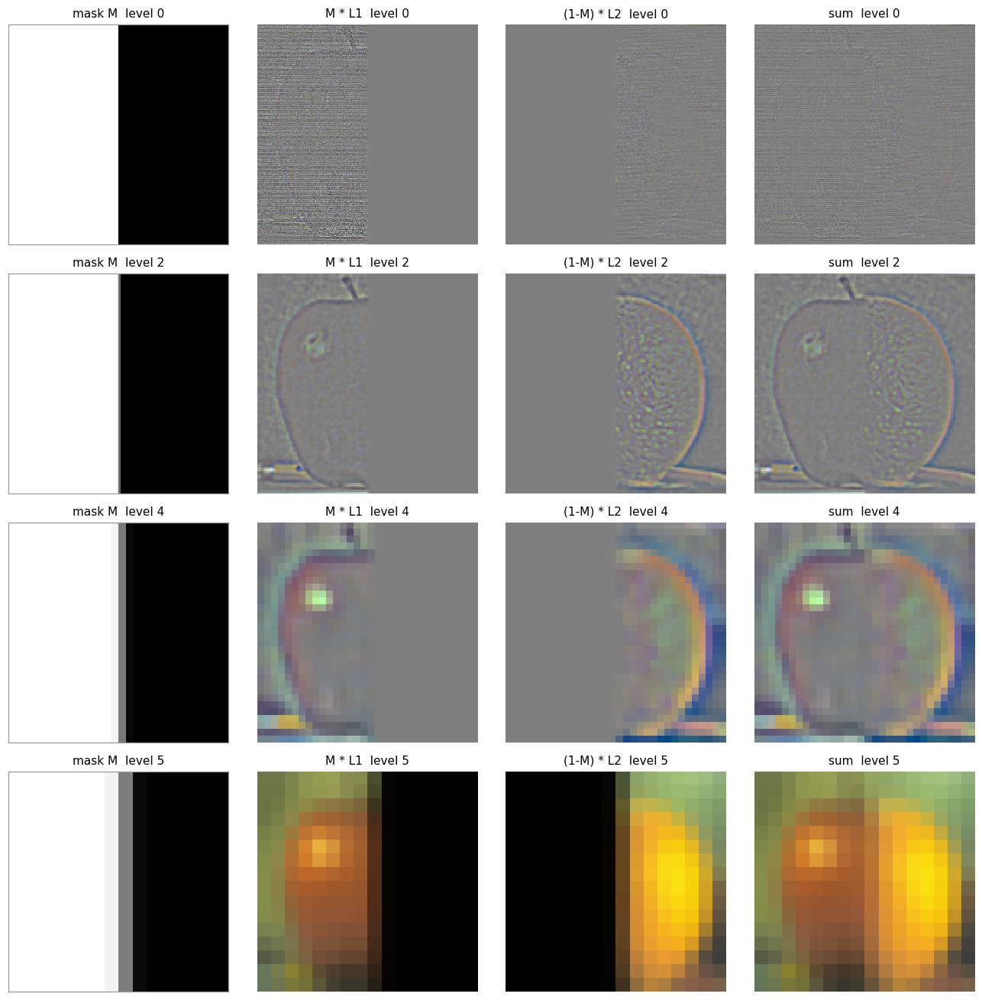

In [ ]:
viz.show_blend_levels(parts, picks=[0, 2, 4, 5], save_path=FIG_DIR / "2_4_oraple_levels.png")

### an eye on the palm 


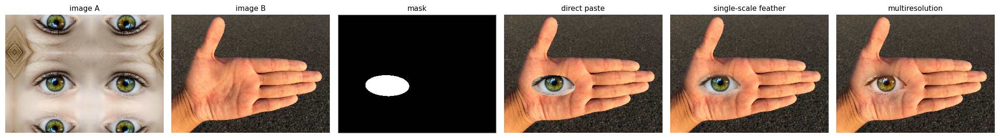

In [ ]:
hand = load_or_demo(HAND, "sunset")
eye = load_or_demo(EYE, "bars")
if find_image(EYE):
    eye = align_images(hand, eye, HAND_PTS, EYE_PTS)
else:
    eye = match_shape(hand, eye)
# mask: ellipse around the eye (x, y) = middle of the two points, radii and tilt tuned by eye
cx = np.mean([p[0] for p in HAND_PTS]); cy = np.mean([p[1] for p in HAND_PTS])
eye_mask = ellipse_mask(hand.shape, center=(cx, cy), radii=(125, 60), angle_deg=-2)
# A = eye (where mask = 1), B = hand
levels = pyramids.max_levels(hand.shape)
eye_multi = multires_blend(eye, hand, eye_mask, levels=levels)
viz.show_blend_comparison(eye, hand, eye_mask,
                          [direct_paste(eye, hand, eye_mask), feather_blend(eye, hand, eye_mask, sigma=15), eye_multi],
                          ["direct paste", "single-scale feather", "multiresolution"],
                          save_path=FIG_DIR / "2_4_eyehand_comparison.png")
save_image(eye_multi, FIG_DIR / "2_4_eyehand.png")

### (irregular masks)


face_pumpkin: mask = polygon_obj (83779 px, 14.9% of the image), levels = 5 (max 7)


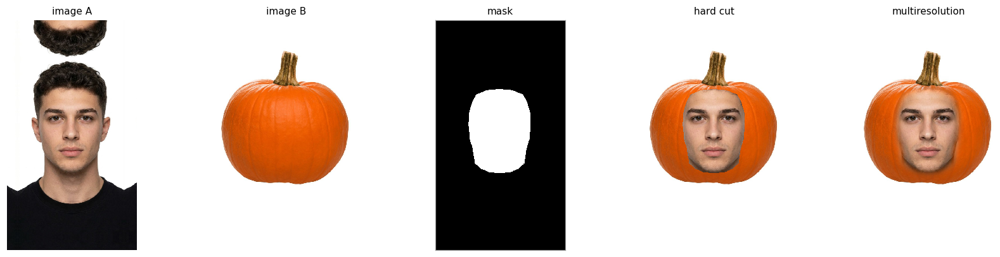

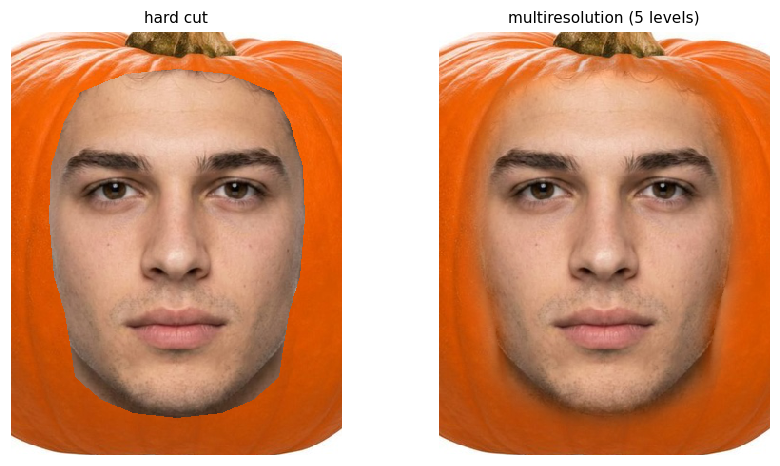

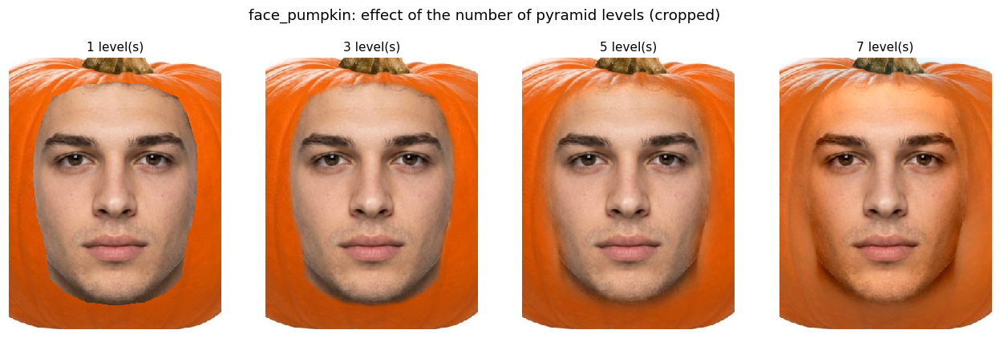

eye_moon: mask = polygon_obj (38674 px, 5.8% of the image), levels = 5 (max 7)


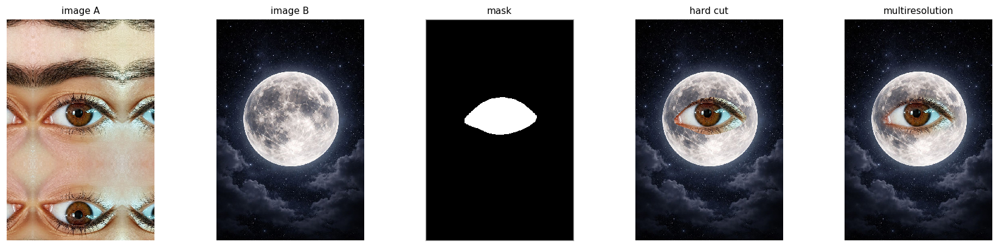

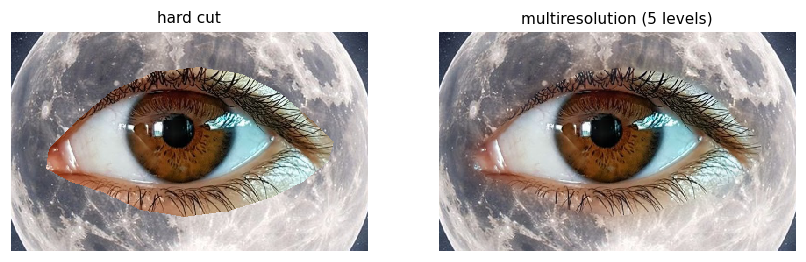

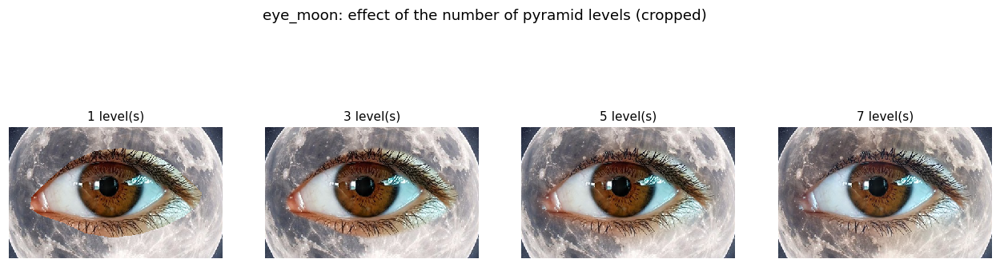

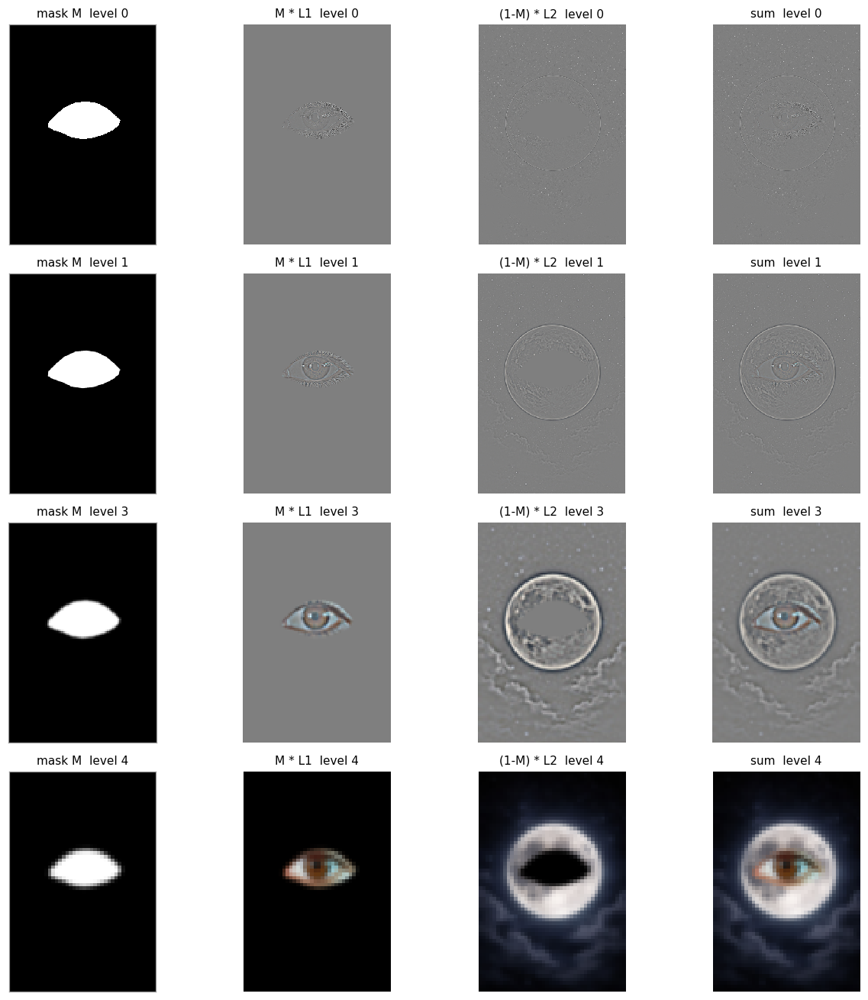

In [ ]:
def make_mask(spec, shape, pair=None):
    kind = spec["kind"]
    if kind == "ellipse":
        return ellipse_mask(shape, spec["center"], spec["radii"], spec.get("angle", 0.0))
    if kind == "polygon":
        return polygon_mask(shape, spec["points"])
    if kind == "polygon_obj":
        # outline traced on the object image -> base coordinates, through the SAME similarity transform
        # that align_images applies to the pixels (z' = a z + b from the two point pairs)
        M = similarity_from_two_points(pair["pts_obj"], pair["pts_base"])
        pts = np.asarray(spec["points"], dtype=np.float64) @ M[:, :2].T + M[:, 2]
        return polygon_mask(shape, np.round(pts))
    if kind == "file":
        return (load_or_demo(spec["path"], "sunset", gray=True) > 0.5).astype(np.float64)
    raise ValueError(f"unknown mask kind {kind!r}")

own_blends = {}
for p in BLEND_PAIRS:
    if find_image(p["base"]) is None or find_image(p["obj"]) is None:
        print(f"[TODO] {p['name']}: put {p['base']!r} and {p['obj']!r} in part2/images/ and fill in BLEND_PAIRS")
        continue
    if not (p["pts_base"] and p["pts_obj"]):
        print(f"[TODO] {p['name']}: fill in pts_base / pts_obj (use show_with_grid on each image)")
        continue
    base = load_or_demo(p["base"], "sunset")
    obj = align_images(base, load_or_demo(p["obj"], "bars"), p["pts_base"], p["pts_obj"])
    m = make_mask(p["mask"], base.shape, p)
    out, parts = multires_blend(obj, base, m, levels=p["levels"], return_parts=True)
    own_blends[p["name"]] = out
    print(f"{p['name']}: mask = {p['mask']['kind']} ({int(m.sum())} px, {100 * m.mean():.1f}% of the image), "
          f"levels = {p['levels']} (max {pyramids.max_levels(base.shape)})")
    viz.show_blend_comparison(obj, base, m, [direct_paste(obj, base, m), out], ["hard cut", "multiresolution"],
                              save_path=FIG_DIR / f"2_4_{p['name']}_comparison.png")
    save_image(out, FIG_DIR / f"2_4_{p['name']}.png")
    ys, xs = np.where(m > 0.5)                           # crop box around the pasted object (+40 px)
    y0, y1, x0, x1 = max(ys.min() - 40, 0), ys.max() + 40, max(xs.min() - 40, 0), xs.max() + 40
    viz.show_row([direct_paste(obj, base, m)[y0:y1, x0:x1], out[y0:y1, x0:x1]],
                 ["hard cut", f"multiresolution ({p['levels']} levels)"], size=4.6,
                 save_path=FIG_DIR / f"2_4_{p['name']}_zoom.png")
    if p.get("sweep"):                                   # number of levels, cropped around the pasted object
        outs = [multires_blend(obj, base, m, levels=n)[y0:y1, x0:x1] for n in p["sweep"]]
        viz.show_row(outs, [f"{n} level(s)" for n in p["sweep"]], size=3.6,
                     suptitle=f"{p['name']}: effect of the number of pyramid levels (cropped)",
                     save_path=FIG_DIR / f"2_4_{p['name']}_levels_sweep.png")
    if p["name"] == BLEND_FAVORITE:
        n = len(parts["la"])
        viz.show_blend_levels(parts, picks=sorted(set([0, n // 3, 2 * n // 3, n - 1])),
                              save_path=FIG_DIR / f"2_4_{p['name']}_levels.png")


### Number of levels
Too few levels = a visible seam at coarse structure; the effect saturates once the mask blur covers the seam.

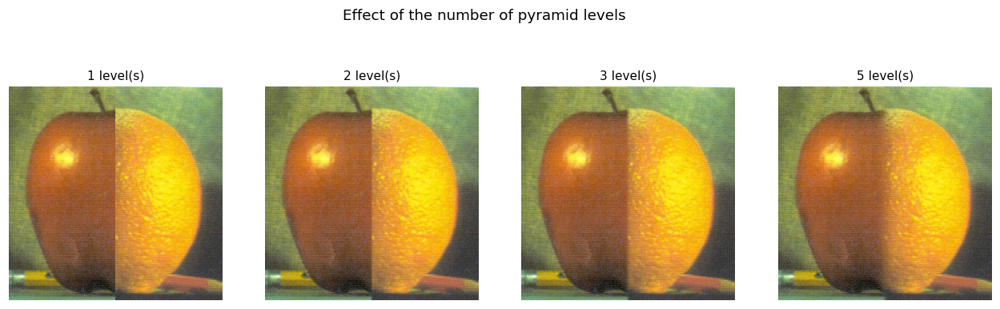

In [ ]:
outs = [multires_blend(A, B, mask, levels=n) for n in (1, 2, 3, 5)]
viz.show_row(outs, [f"{n} level(s)" for n in (1, 2, 3, 5)], suptitle="Effect of the number of pyramid levels",
             size=3.6, save_path=FIG_DIR / "2_4_levels_sweep.png")